# Markov Chain

#### Notes:
- experiment with states and what other data can be added 
- cross validation
- take some structure ideas from three splits notebook
## Requirements

In [183]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, log_loss, brier_score_loss, confusion_matrix,
    accuracy_score, recall_score, precision_score,
    precision_recall_curve, average_precision_score,
)

## Data

In [184]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


 ## Origional Markov Chain 

 The code from the first sprint has been adjusted to fit the format of the data in this project but is the same in how it runs. This is so we can use it as a consistent baseline for the adjustments made to improve the model.

In [185]:
state_names = ["current", "1_month_late", "2_months_late", "3plus_months_late"]
K_ow = 4

def to_state_ow(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p <= 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s
S_tr = to_state_ow(train[pay_cols].values)
S_va = to_state_ow(validation[pay_cols].values)
S_te = to_state_ow(test[pay_cols].values)
y_tr_a, y_va_a, y_te_a = (np.asarray(v).astype(int) for v in (y_tr, y_va, y_te))
# 1) transition matrix (TRAIN only, Laplace smoothing)
counts = np.ones((K_ow, K_ow))
for a, b in zip(S_tr[:, :-1].ravel(), S_tr[:, 1:].ravel()):
    counts[a, b] += 1
P_ow = counts / counts.sum(axis=1, keepdims=True)
# 2) default rate by latest state, shrunk toward the global rate (TRAIN only)
latest_tr = S_tr[:, -1]
global_rate = y_tr_a.mean()
shrink = 20
risk_by_state = np.array([
    (y_tr_a[latest_tr == k].sum() + shrink * global_rate) / ((latest_tr == k).sum() + shrink)
    for k in range(K_ow)
])
# 3) one-step Markov projection: P(default) = sum_j P[latest, j] * risk[j]
def predict_onestep(S):
    return P_ow[S[:, -1]] @ risk_by_state
p_mk_onestep_va = predict_onestep(S_va)
p_mk_onestep_te = predict_onestep(S_te)
# inspect
print(pd.DataFrame(P_ow, index=state_names, columns=state_names).round(3)) 
print("\n")
print(pd.Series(risk_by_state, index=state_names).round(3))
print("\n")
print("val AUC", roc_auc_score(y_va_a, p_mk_onestep_va),
      "test AUC", roc_auc_score(y_te_a, p_mk_onestep_te),
      "test logloss", log_loss(y_te_a, p_mk_onestep_te),
      )

                   current  1_month_late  2_months_late  3plus_months_late
current              0.939         0.014          0.047              0.000
1_month_late         0.042         0.875          0.042              0.042
2_months_late        0.255         0.102          0.578              0.065
3plus_months_late    0.104         0.085          0.281              0.531


current              0.142
1_month_late         0.322
2_months_late        0.686
3plus_months_late    0.676
dtype: float64


val AUC 0.7098305994570099 test AUC 0.7088284613042087 test logloss 0.46078179195670793


This first model is good because of its simpicity which makes it easier to interpret, 

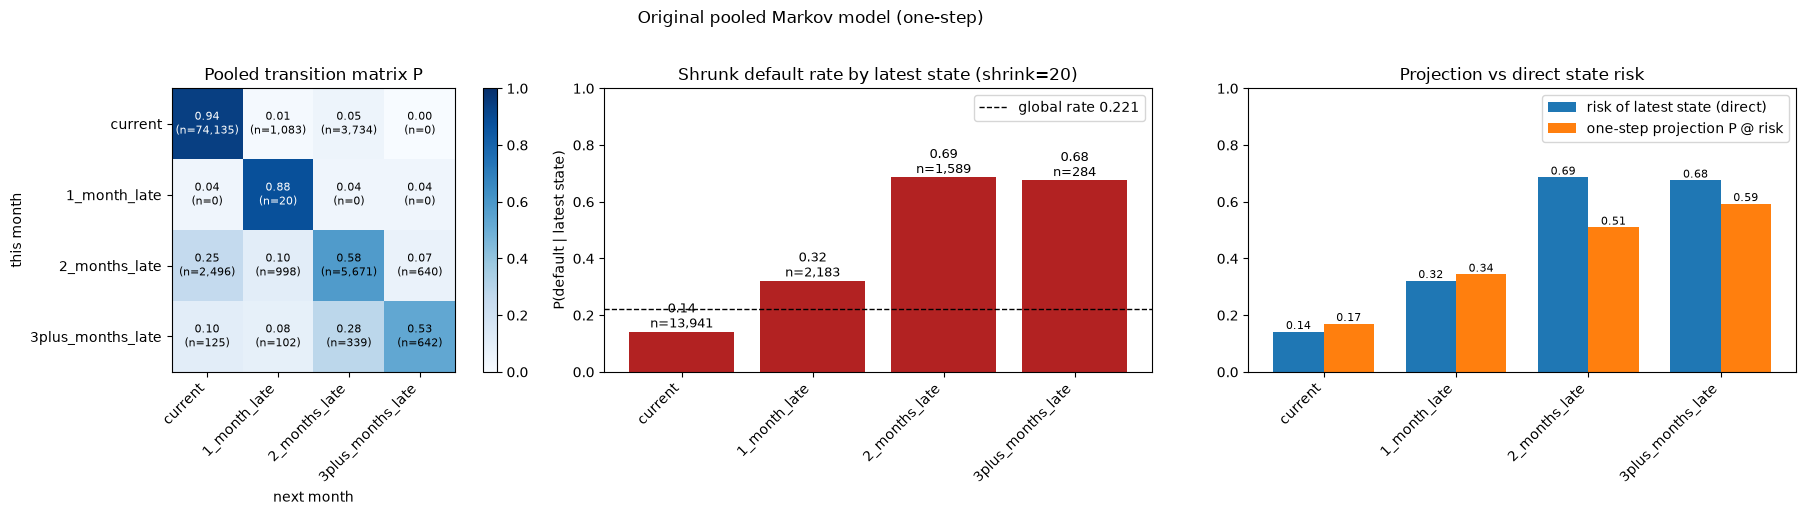

In [186]:
counts_raw = counts - 1                                  # remove Laplace +1 -> real transitions
n_latest   = np.bincount(latest_tr, minlength=K_ow)      # customers per latest state
obs_rate   = np.array([y_tr_a[latest_tr == k].mean() if n_latest[k] else np.nan for k in range(K_ow)])
proj_risk  = P_ow @ risk_by_state                        # what predict_onestep gives per latest state

fig, axs = plt.subplots(1, 3, figsize=(20, 5))

# (a) pooled transition matrix with raw counts
ax = axs[0]
im = ax.imshow(P_ow, cmap="Blues", vmin=0, vmax=1)
for i in range(K_ow):
    for j in range(K_ow):
        ax.text(j, i, f"{P_ow[i, j]:.2f}\n(n={int(counts_raw[i, j]):,})",
                ha="center", va="center", fontsize=8,
                color="white" if P_ow[i, j] > 0.6 else "black")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks(range(K_ow)); ax.set_xticklabels(state_names, rotation=45, ha="right")
ax.set_yticks(range(K_ow)); ax.set_yticklabels(state_names)
ax.set_xlabel("next month"); ax.set_ylabel("this month"); ax.set_title("Pooled transition matrix P")

# (b) default rate by latest state
ax = axs[1]
x = np.arange(K_ow)
b = ax.bar(x, risk_by_state, color="firebrick")
ax.axhline(global_rate, color="k", ls="--", lw=1, label=f"global rate {global_rate:.3f}")
for xi, r, n in zip(x, risk_by_state, n_latest):
    ax.text(xi, r, f"{r:.2f}\nn={n:,}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(state_names, rotation=45, ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("P(default | latest state)")
ax.set_title(f"Shrunk default rate by latest state (shrink={shrink})"); ax.legend()

# (c) shrunk rate vs one-step projection
ax = axs[2]
w = 0.38
ax.bar(x - w/2, risk_by_state, w, label="risk of latest state (direct)")
ax.bar(x + w/2, proj_risk,     w, label="one-step projection P @ risk")
for xi, a, p in zip(x, risk_by_state, proj_risk):
    ax.text(xi - w/2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(xi + w/2, p, f"{p:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(state_names, rotation=45, ha="right")
ax.set_ylim(0, 1); ax.set_title("Projection vs direct state risk"); ax.legend()

plt.suptitle("Original pooled Markov model (one-step)", y=1.02)
plt.tight_layout(); plt.show()

## Two Class Chain
To build on work from the previous sprint the new model uses a two class markov chain classifier. The train data is seperated into defaulter and non-defaulter and the model learns how each class moves between payment status states. The train data is scored based on how much more likely their sequence is from the default chain as opposed to the non default chain. This allows the model to consider history as opposed to the pooled data only considering the most recent state. It is likely the dynamics among these two classes are different so when combining them it compresses to the mean of both. The average of groups is less significant in this instance as what is most important is the behavour of the defaulters. A drawback of this is that since defaulters only make up about 22% of the dataset the default chain is sparse in data. The model is also more likely to overfit so it is important to compare performance of train data with test. This does not adress the time homogeniousity or first order dependence of the matrices constructed.





In [187]:
#function for each split of the Markov model
#original 5 states
def to_state_5full(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p >= 2] = 4
    return s

#merges -2, -1 and 0 into one state (not late)
def to_state_4nolate(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s

# ---- state mappings ----
def make_to_state(mapping, top):
    # mapping: dict raw value -> state; any raw value >= top maps to the last state
    def f(p):
        p = np.asarray(p); s = np.empty(p.shape, dtype=int)
        for raw, st in mapping.items():
            s[p == raw] = st
        s[p >= top] = max(mapping.values()) + 1 if top > max(mapping) else mapping[top]
        return s
    return f

## Two-class Markov chain: construction

### 1. Data and states
Each customer has a payment-status sequence over $T = 6$ months, ordered oldest to most recent (`PAY_6, ..., PAY_1`), and a label $y \in \{0, 1\}$ ($1$ = default next month). A state map $g$ sends each raw PAY value to one of $K$ states:

$$x_t = g(\text{PAY}_t) \in \{1, \dots, K\}, \qquad \mathbf{x} = (x_1, x_2, \dots, x_T).$$

### 2. Fit one chain per class (train split only)
Let $\mathcal{D}_c = \{ i : y_i = c \}$ for $c \in \{0, 1\}$ and let $\alpha = 1$ be the Laplace constant.

**Initial distribution** (state in the first month):

$$\pi_c(s) = \frac{\alpha + \sum_{i \in \mathcal{D}_c} \mathbf{1}[x_{i,1} = s]}{|\mathcal{D}_c| + K\alpha}.$$

**Transition matrix** from pooled consecutive pairs:

$$N_c(a,b) = \sum_{i \in \mathcal{D}_c} \sum_{t=1}^{T-1} \mathbf{1}[x_{i,t} = a,\; x_{i,t+1} = b],$$

$$P_c(a,b) = \frac{N_c(a,b) + \alpha}{\sum_{b'} N_c(a,b') + K\alpha}, \qquad \sum_{b} P_c(a,b) = 1.$$

### 3. Sequence likelihood under each class
Assuming a first-order, time-homogeneous Markov chain:

$$\Pr(\mathbf{x} \mid y = c) = \pi_c(x_1) \prod_{t=1}^{T-1} P_c(x_t, x_{t+1}).$$

### 4. Posterior odds (Bayes' rule)
With prior $\hat{p} = \Pr(y = 1)$ estimated on train:

$$\frac{\Pr(y=1 \mid \mathbf{x})}{\Pr(y=0 \mid \mathbf{x})}
= \frac{\Pr(\mathbf{x} \mid y=1)}{\Pr(\mathbf{x} \mid y=0)} \cdot \frac{\hat{p}}{1-\hat{p}}.$$

Taking logs gives the score used in the code (`llr`):

$$s(\mathbf{x}) = \underbrace{\log\frac{\pi_1(x_1)}{\pi_0(x_1)}}_{\text{start}}
+ \sum_{t=1}^{T-1} \underbrace{\log\frac{P_1(x_t, x_{t+1})}{P_0(x_t, x_{t+1})}}_{\text{transition } t}
+ \underbrace{\log\frac{\hat{p}}{1-\hat{p}}}_{\text{prior}}.$$

Each transition contributes its log-ratio $\lambda(a,b) = \log P_1(a,b) - \log P_0(a,b)$, the quantity shown in the log-ratio heatmap. $\lambda > 0$ pushes towards default; $\lambda < 0$ pushes away.

### 5. Calibration (validation split)
The chain's independence assumptions make $s$ overconfident, so $s$ is mapped to a probability by logistic (Platt) scaling fitted on the **validation** set:

$$\Pr(y = 1 \mid \mathbf{x}) = \sigma\big(a\, s(\mathbf{x}) + b\big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

If $a = 1$ and $b = 0$, this reduces to the exact Bayes posterior.

### 6. Assumptions and limitations
- **First order:** $x_{t+1}$ depends only on $x_t$, not on earlier history.
- **Time-homogeneous:** the same $P_c$ applies at every step.
- **Sparse classes:** defaulters are about 22% of the data, so $P_1$ rests on fewer transitions. Rows with small $\sum_b N_c(a,b)$ are dominated by $\alpha$.
- **Leakage control:** $\pi_c, P_c, \hat{p}$ use train only; $(a, b)$ uses validation only; test is held out for evaluation.

In [188]:
# ---- generic Markov model ----
def fit_chain(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

def llr(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov(name, to_state, K):
    S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))
    init0, P0 = fit_chain(S_tr[y_tr == 0], K)      # TRAIN only
    init1, P1 = fit_chain(S_tr[y_tr == 1], K)
    m = dict(name=name, K=K, to_state=to_state, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(y_tr.mean() / (1 - y_tr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr(S_tr, m), llr(S_va, m), llr(S_te, m)
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION
    m["p_va"] = m["platt"].predict_proba(m["sc_va"].reshape(-1, 1))[:, 1]
    m["p_te"] = m["platt"].predict_proba(m["sc_te"].reshape(-1, 1))[:, 1]
    return m

# ---- build models ----
markov_models = {
    "mk5_full":     build_markov("mk5_full",     to_state_5full,     5),
    "mk4_nolate":   build_markov("mk4_nolate",   to_state_4nolate,   4),
}

# named probability vectors, matching your existing p_mk_va / p_mk_te style
p_mk5_full_va,     p_mk5_full_te     = markov_models["mk5_full"]["p_va"],     markov_models["mk5_full"]["p_te"]
p_mk4_nolate_va,   p_mk4_nolate_te   = markov_models["mk4_nolate"]["p_va"],   markov_models["mk4_nolate"]["p_te"]

## Matrix Heatmaps

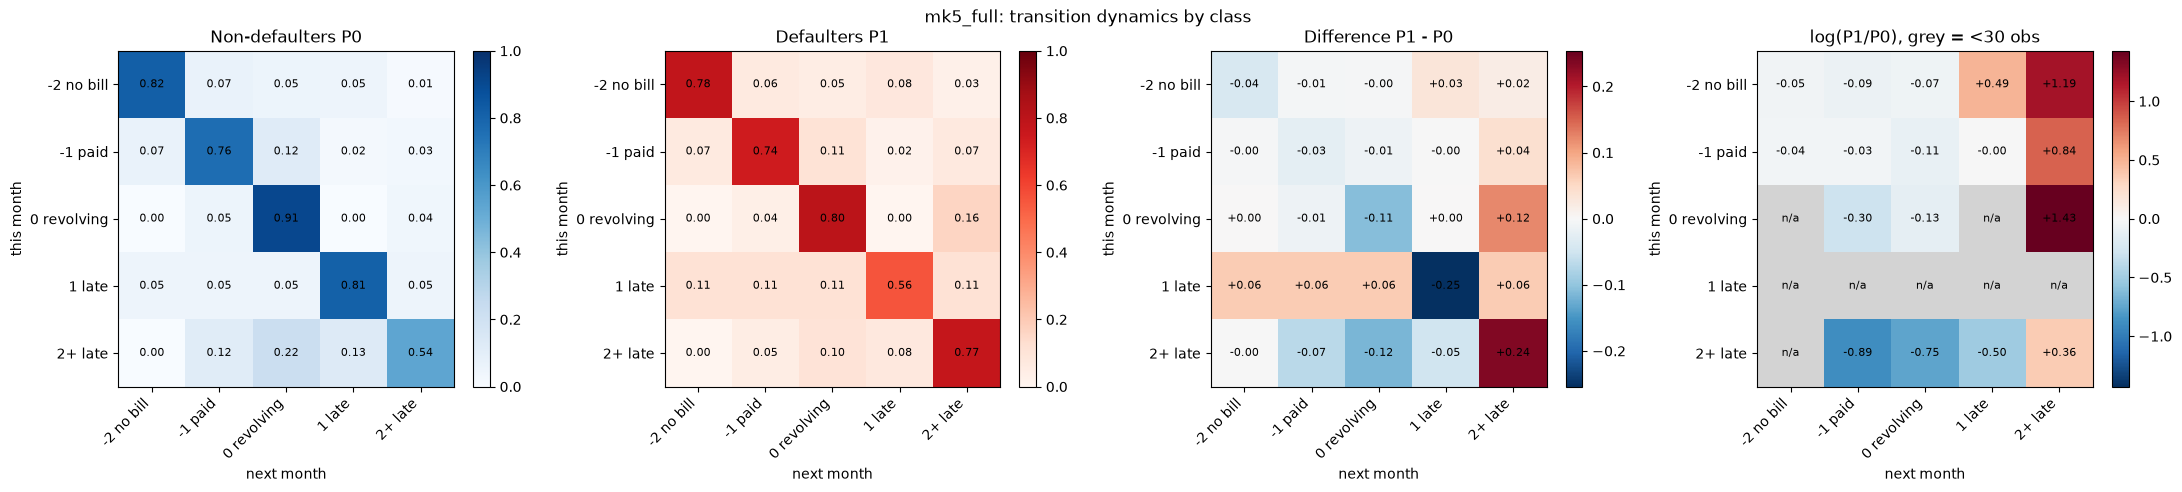

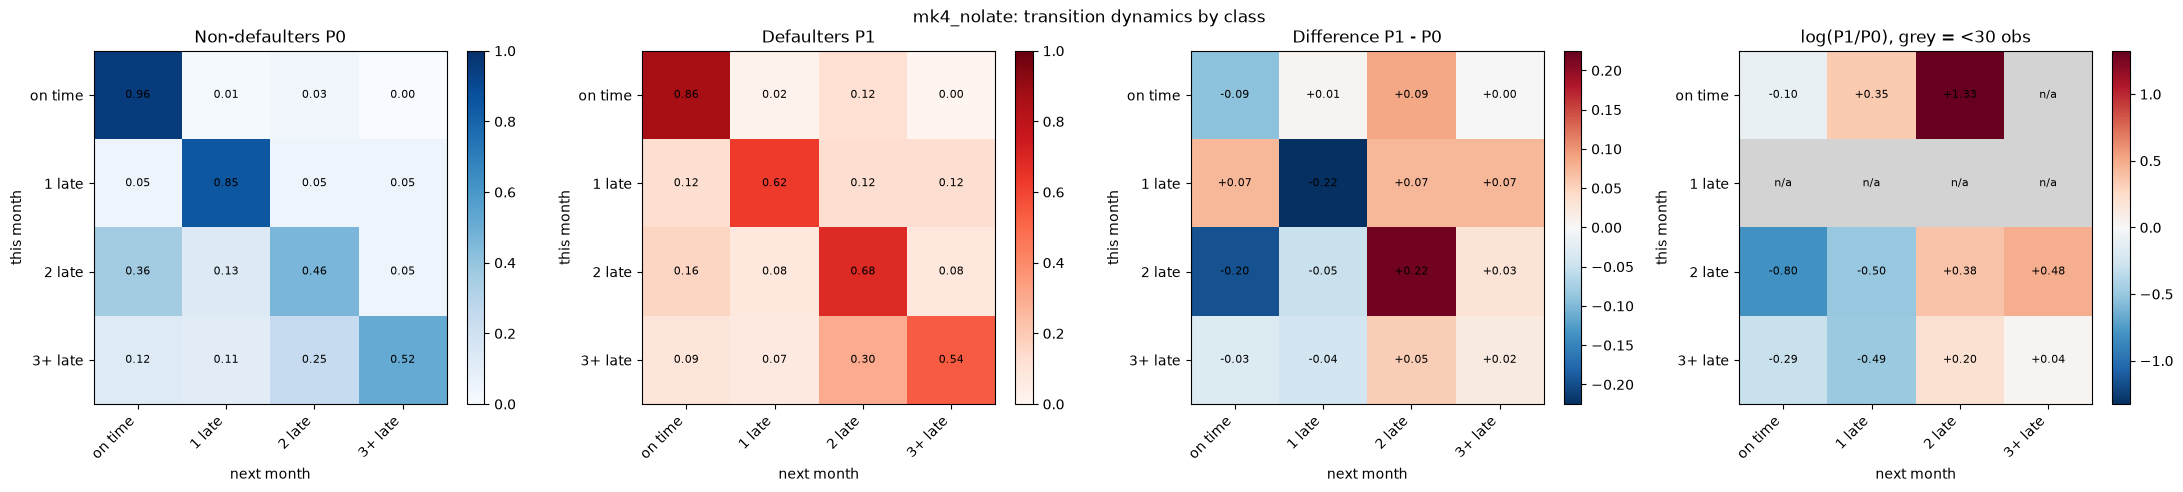

In [189]:
labels = {
    "mk5_full":     ["-2 no bill", "-1 paid", "0 revolving", "1 late", "2+ late"],
    "mk4_nolate":   ["on time", "1 late", "2 late", "3+ late"],
}

def raw_counts(S, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return C

def _prep(key, models, labels, data, pay_cols, y):
    m = models[key]; K = m["K"]
    lab = labels[key] if isinstance(labels, dict) else list(labels)
    assert len(lab) == K, f"{key}: {len(lab)} labels but K={K}"
    y = np.asarray(y)
    S = m["to_state"](data[pay_cols].values)
    C0, C1 = raw_counts(S[y == 0], K), raw_counts(S[y == 1], K)
    return m, K, lab, C0, C1

def _tick_labels(ax, lab):
    K = len(lab)
    ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=45, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(lab)
    ax.set_xlabel("next month"); ax.set_ylabel("this month")


def plot_class_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(22, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)
    P0, P1 = m["P0"], m["P1"]
    low = np.minimum(C0, C1) < min_n
    diff, logr = P1 - P0, np.log(P1) - np.log(P0)
    logr_m = np.ma.array(logr, mask=low)
    cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
    dl, ll = np.abs(diff).max(), np.abs(logr_m).max()

    fig, axs = plt.subplots(1, 4, figsize=figsize)
    panels = [(P0, "Non-defaulters P0", "Blues", 0, 1, ".2f"),
              (P1, "Defaulters P1", "Reds", 0, 1, ".2f"),
              (diff, "Difference P1 - P0", cm, -dl, dl, "+.2f"),
              (logr_m, f"log(P1/P0), grey = <{min_n} obs", cm, -ll, ll, "+.2f")]
    for ax, (M, t, cmap, lo, hi, fmt) in zip(axs, panels):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                txt = "n/a" if (M is logr_m and low[i, j]) else format(M[i, j], fmt)
                ax.text(j, i, txt, ha="center", va="center", fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046)
        _tick_labels(ax, lab)
    fig.suptitle(f"{key}: transition dynamics by class")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1, low=low)



for k in markov_models:
    plot_class_heatmaps(k, markov_models, labels, train, pay_cols, y_tr)



### Interpretation of Heatmaps

#### mk5
The P0 and P1 matrices both have strong diagonal enteries. Defaulters are less stable in the not late states which matches general intuition which is a good sign. The weakest P0 diagonal being the 2+ late with a value of only 0.54 Here there is a 34% chance of returning to an on time payment. This behavour is not seen in P1 which has a much stronger 0.77 diagonal entry and only a 15% chance of returning to a non late status. What is less expected is the non defaulters are more likely to remain 1 month over than defaulters. This result is likely an artifact of smoothing due to the limited data size

#### mk4
A similar issue arrises in this split which further reinforces the fact that it is a problem caused by the data. To investivage this we can take a look at the raw counts for each transition matrix and flag any with very few transitions.
## Count Heatmaps

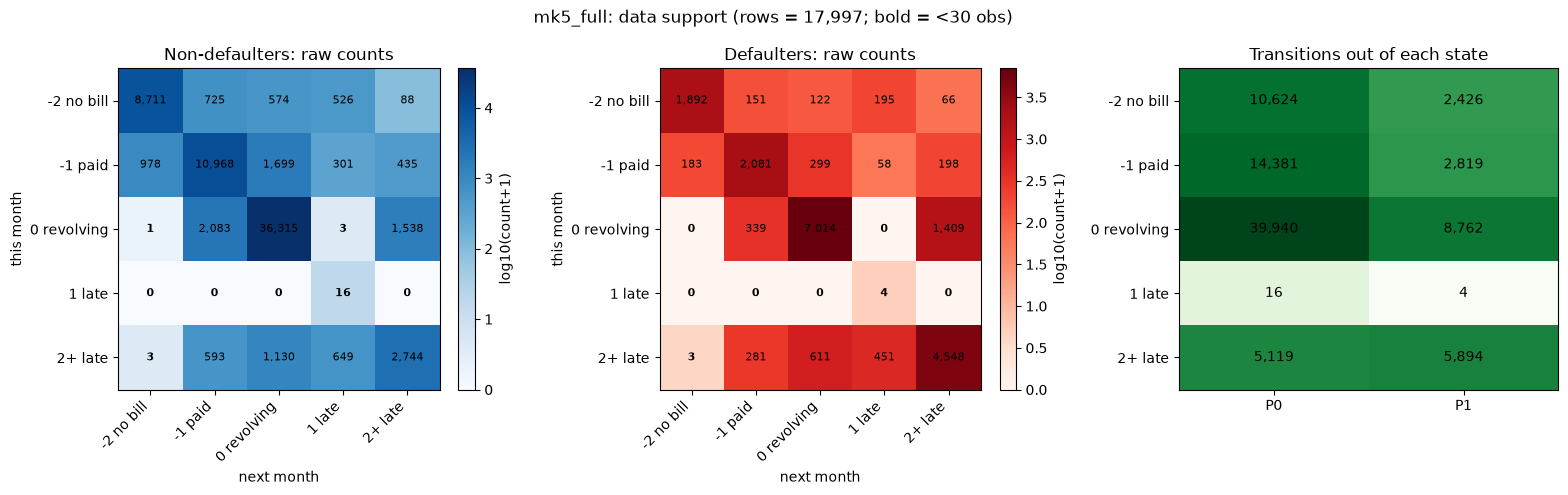

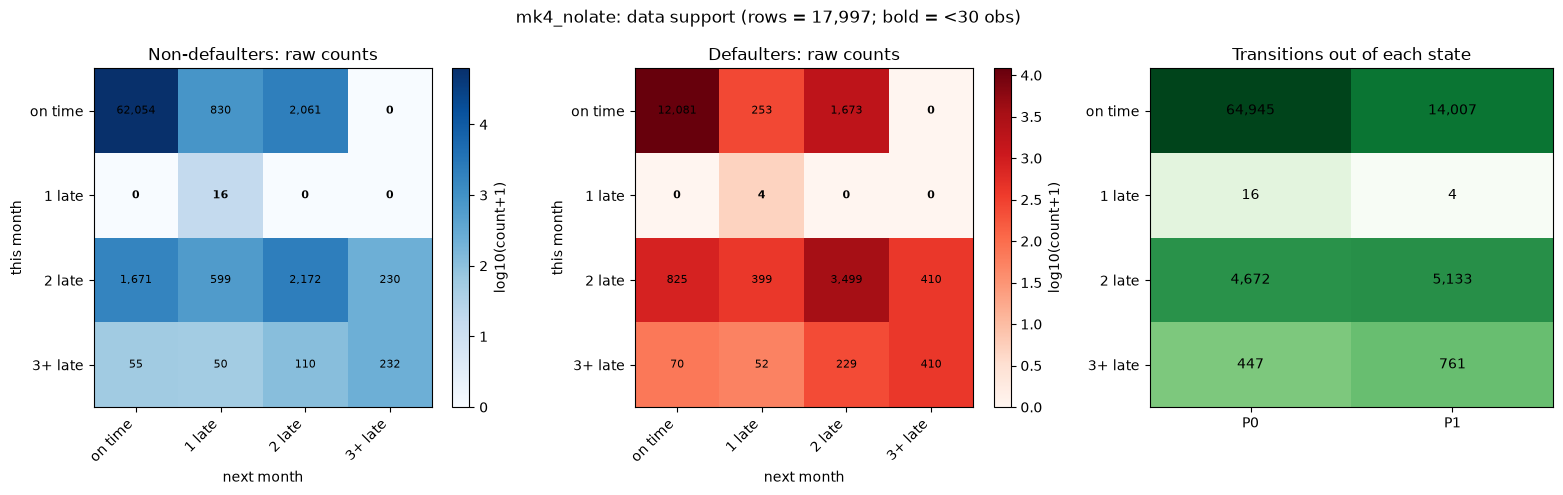

In [190]:
MIN_N = 30  # cells with fewer raw transitions than this are flagged as unreliable

def plot_count_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(16, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)

    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for ax, C, t, cmap in [(axs[0], C0, "Non-defaulters: raw counts", "Blues"),
                           (axs[1], C1, "Defaulters: raw counts", "Reds")]:
        im = ax.imshow(np.log10(C + 1), cmap=cmap); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, f"{C[i, j]:,}", ha="center", va="center", fontsize=8,
                        fontweight="bold" if C[i, j] < min_n else "normal")
        plt.colorbar(im, ax=ax, fraction=0.046).set_label("log10(count+1)")
        _tick_labels(ax, lab)

    row_n = np.vstack([C0.sum(1), C1.sum(1)]).T
    axs[2].imshow(np.log10(row_n + 1), cmap="Greens", aspect="auto")
    for i in range(K):
        for c in range(2):
            axs[2].text(c, i, f"{row_n[i, c]:,}", ha="center", va="center")
    axs[2].set_xticks([0, 1]); axs[2].set_xticklabels(["P0", "P1"])
    axs[2].set_yticks(range(K)); axs[2].set_yticklabels(lab)
    axs[2].set_title("Transitions out of each state")

    fig.suptitle(f"{key}: data support (rows = {len(data):,}; bold = <{min_n} obs)")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1)

for k in markov_models:
    plot_count_heatmaps(k, markov_models, labels, train, pay_cols, y_tr)

This count cell clearly displays the data issue. The simplest way to get around this issue is to shift the boundaries of the states so state 1 is absorbed by another. It is not obvious exactly which way would be best to split the data. For the 5 state chain we could either merge 1 into 2+, or make a 1-2 and a 3+ state, or even merge 1 and 0. Merging 1 and 0 seems the least reasonable choice as you are putting an on time payment with a late payment. We can calculate different splits and see how it affects some basic performance metrics to see if any are the obvious winner.


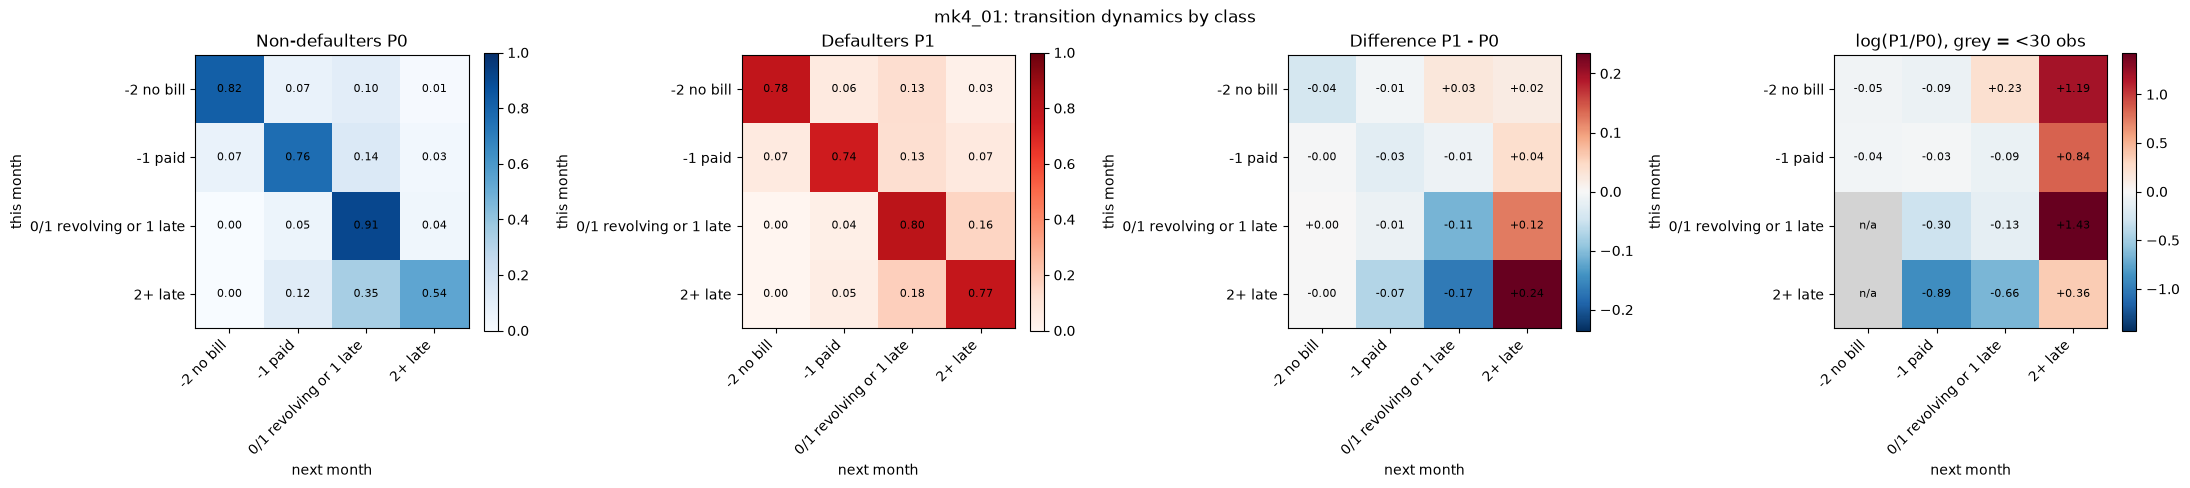

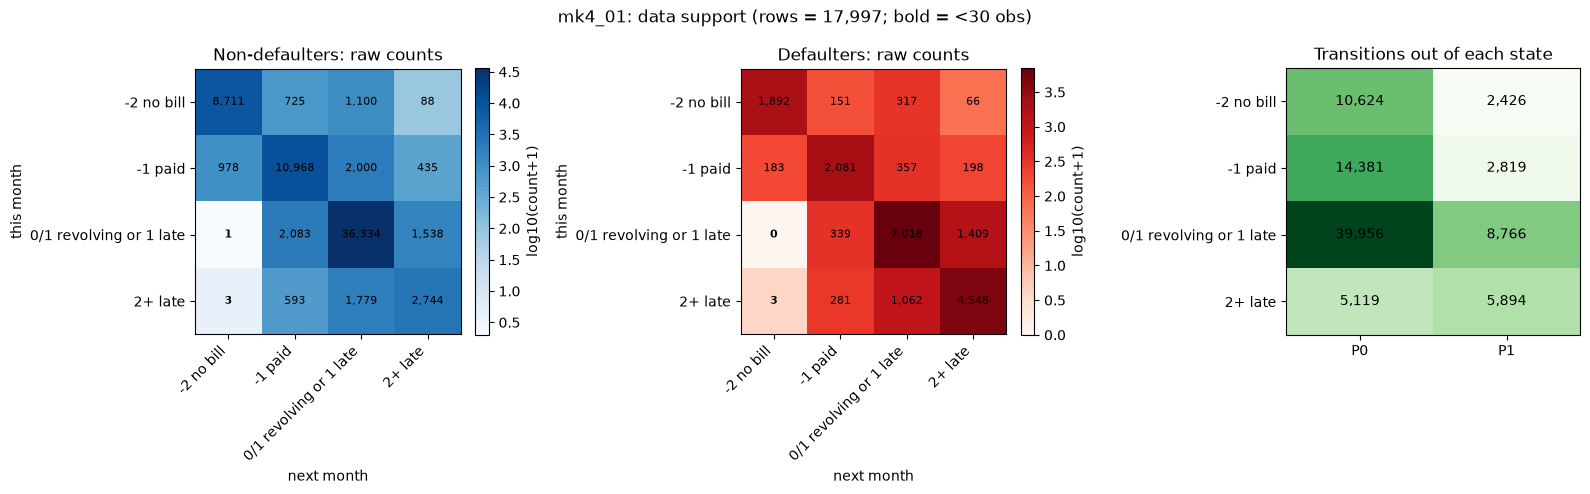

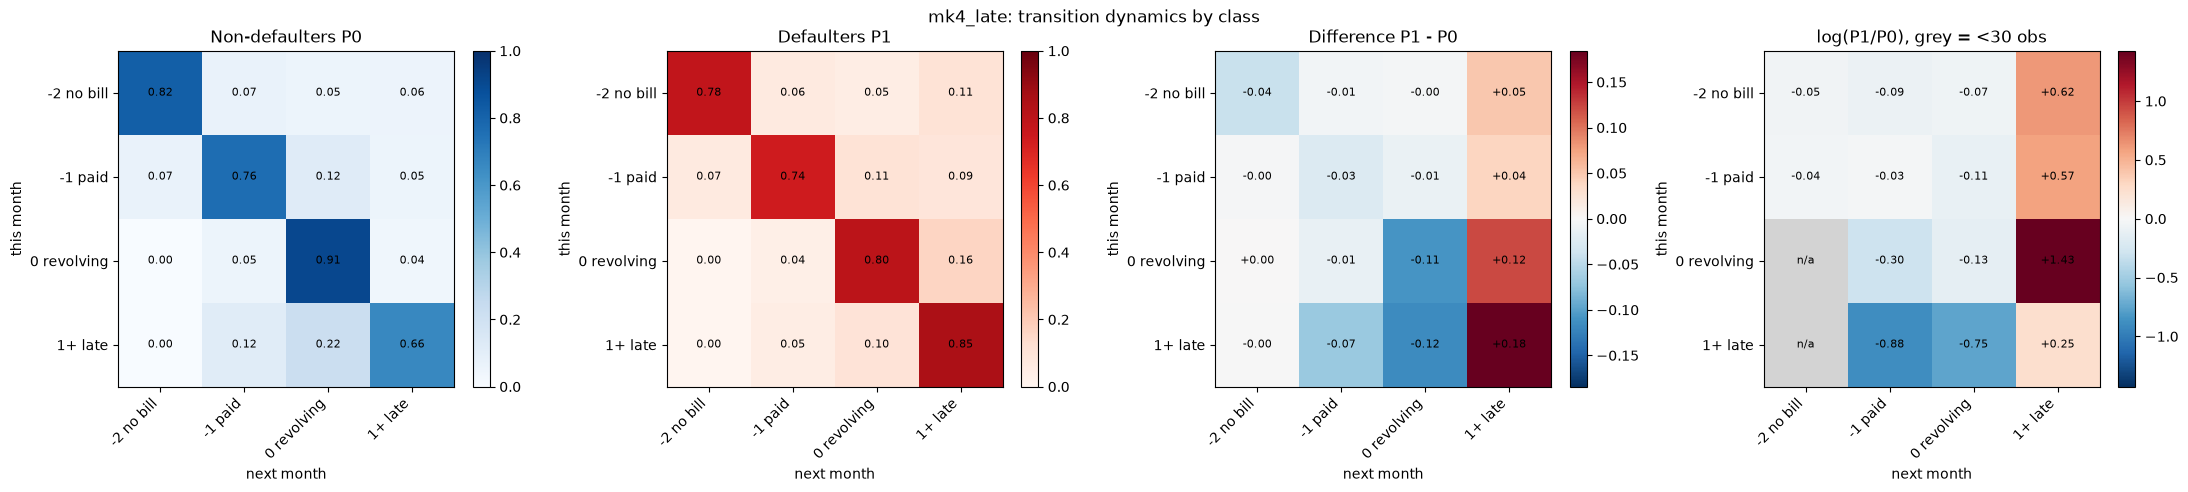

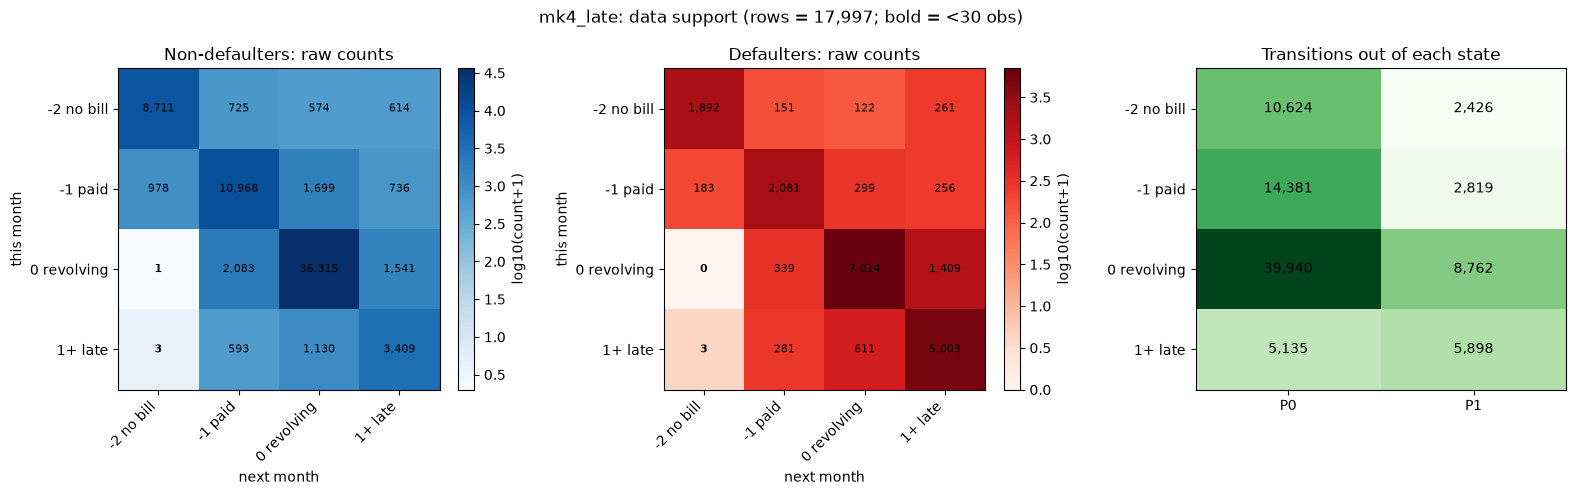

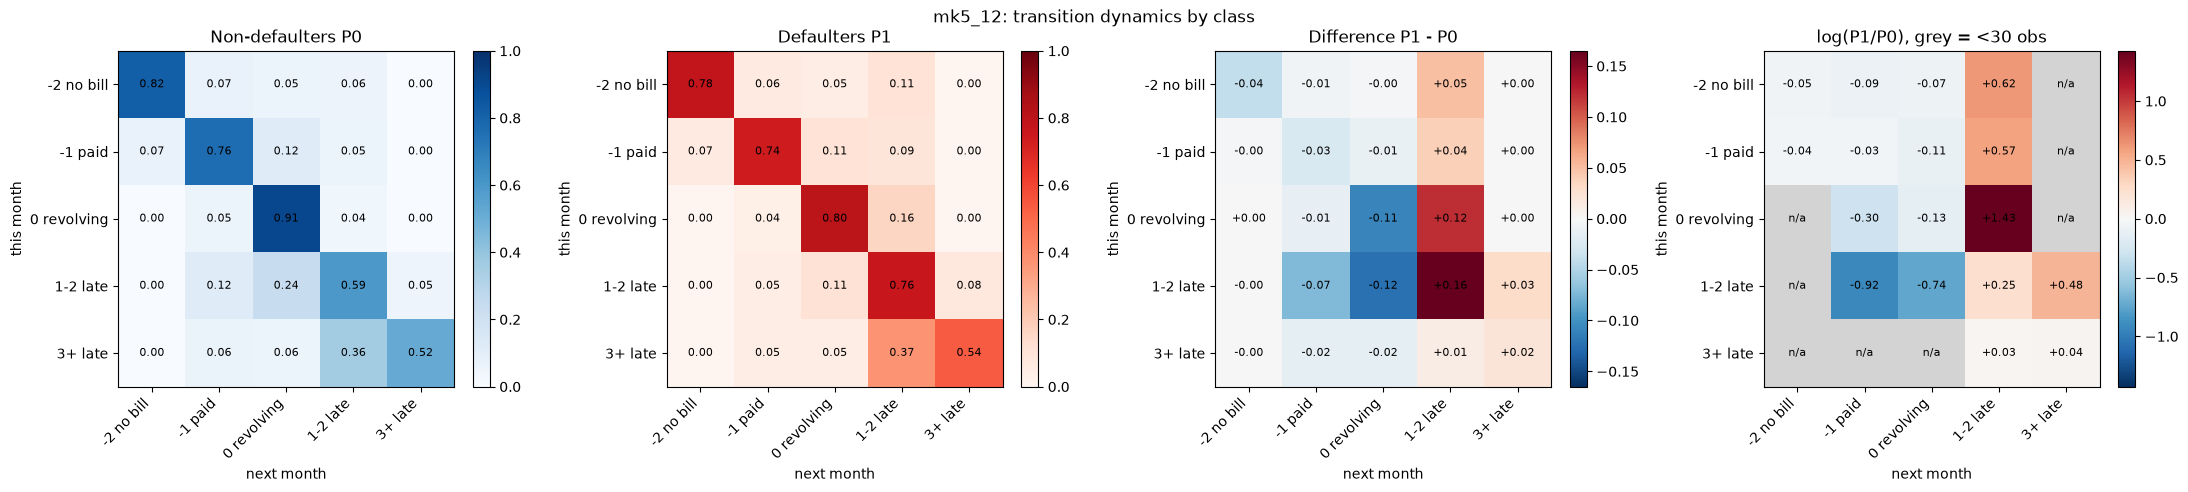

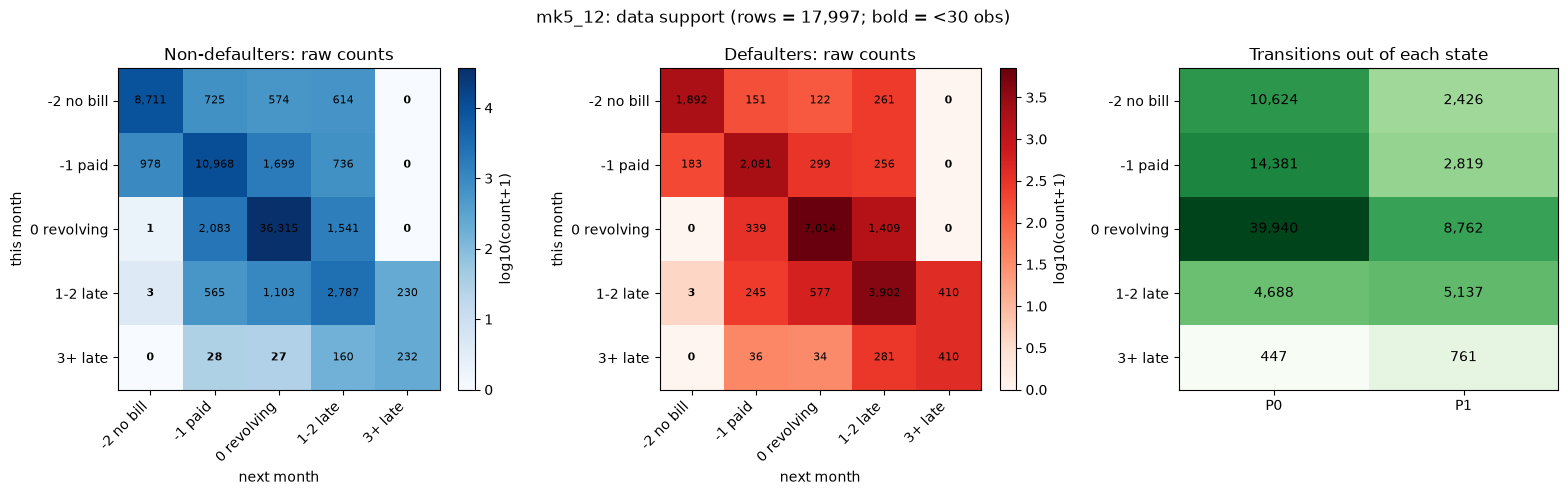

In [191]:
#merge 0 and 1
def to_state_4_01(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 2; s[p >= 2] = 3
    return s
#merge 1 and 2
def to_state_5_12(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p == 2] = 3; s[p >= 3] = 4
    return s
#all late states are merged into one state
def to_state_4_late(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p >= 1] = 3
    return s

markov_models2 = {
    "mk4_01":     build_markov("mk4_01",     to_state_4_01,     4),
    "mk4_late":   build_markov("mk4_late",   to_state_4_late,   4),
    "mk5_12":   build_markov("mk5_12",   to_state_5_12,   5),
}
labels2 = {
    "mk4_01":   ["-2 no bill", "-1 paid", "0/1 revolving or 1 late", "2+ late"],
    "mk4_late": ["-2 no bill", "-1 paid", "0 revolving", "1+ late"],
    "mk5_12":   ["-2 no bill", "-1 paid", "0 revolving", "1-2 late", "3+ late"],
}
for k in markov_models2:
    plot_class_heatmaps(k, markov_models2, labels2, train, pay_cols, y_tr)
    plot_count_heatmaps(k, markov_models2, labels2, train, pay_cols, y_tr)

Analysis of new heat maps

## Performance Metrics

In [192]:


ys = {"train": y_tr, "val": y_va, "test": y_te}   # target arrays per split

def _probs(m, split):
    key = {"train": "p_tr", "val": "p_va", "test": "p_te"}[split]
    if key in m:
        return np.asarray(m[key])
    sc = m[{"train": "sc_tr", "val": "sc_va", "test": "sc_te"}[split]]
    return m["platt"].predict_proba(np.asarray(sc).reshape(-1, 1))[:, 1]

def _grid(n, ncols=3, size=(5, 4.5)):
    nrows = int(np.ceil(n / ncols)); ncols = min(n, ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    return fig, axs.ravel()

def _bar_by_split(models, values, title, ylabel, ylim=None):
    names, splits = list(models), list(next(iter(values.values())))
    w = 0.8 / len(splits); x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(1.8 * len(names) + 4, 4.5))
    for i, s in enumerate(splits):
        vals = [values[n][s] for n in names]
        bars = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

# ---------- one function per metric ----------

def plot_auc(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: roc_auc_score(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    lo = min(v for d in vals.values() for v in d.values())
    _bar_by_split(models, vals, "ROC AUC", "AUC", ylim=(max(0.5, lo - 0.05), min(1, lo + 0.25)))
    return vals

def plot_logloss(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: log_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Log loss (lower is better)", "log loss")
    return vals

def plot_brier(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: brier_score_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Brier score (lower is better)", "Brier")
    return vals

def plot_roc(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        fpr, tpr, _ = roc_curve(ys[split], _probs(m, split))
        ax.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(ys[split], _probs(m, split)):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curves ({split})"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

def plot_pr(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p, r, _ = precision_recall_curve(ys[split], _probs(m, split))
        ax.plot(r, p, label=f"{n} (AP {average_precision_score(ys[split], _probs(m, split)):.3f})")
    ax.axhline(np.mean(ys[split]), color="k", ls="--", lw=1, label="base rate")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-recall ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_calibration(models, ys=ys, split="test", n_bins=10, strategy="quantile"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        frac, mean_p = calibration_curve(ys[split], _probs(m, split), n_bins=n_bins, strategy=strategy)
        ax.plot(mean_p, frac, "o-", label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(f"Calibration ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_gains(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        y = np.asarray(ys[split]); order = np.argsort(-_probs(m, split))
        cum = np.cumsum(y[order]) / y.sum()
        ax.plot(np.arange(1, len(y) + 1) / len(y), cum, label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Fraction of customers (highest risk first)")
    ax.set_ylabel("Fraction of defaulters captured")
    ax.set_title(f"Cumulative gains ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_score_distribution(models, ys=ys, split="test", bins=40):
    sc_key = {"train": "sc_tr", "val": "sc_va", "test": "sc_te"}[split]
    fig, axs = _grid(len(models)); y = np.asarray(ys[split])
    for ax, (n, m) in zip(axs, models.items()):
        sc = np.asarray(m[sc_key]); lo, hi = np.percentile(sc, [0.5, 99.5])
        ax.hist(sc[y == 0], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="non-default")
        ax.hist(sc[y == 1], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="default")
        ax.set_title(n); ax.set_xlabel("LLR score"); ax.legend()
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Score distribution by class ({split})"); plt.tight_layout(); plt.show()

def best_threshold(m, y_val, y_split="val"):
    fpr, tpr, thr = roc_curve(y_val, _probs(m, y_split))
    return thr[np.argmax(tpr - fpr)]

def plot_confusion(models, ys=ys, split="test", thresholds=None, normalize=True):
    fig, axs = _grid(len(models))
    for ax, (n, m) in zip(axs, models.items()):
        t = (best_threshold(m, ys["val"]) if thresholds is None
             else thresholds[n] if isinstance(thresholds, dict) else thresholds)
        pred = (_probs(m, split) >= t).astype(int)
        cm_ = confusion_matrix(ys[split], pred)
        show = cm_ / cm_.sum(1, keepdims=True) if normalize else cm_
        ax.imshow(show, cmap="Blues", vmin=0, vmax=show.max())
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm_[i, j]:,}\n({show[i, j]:.0%})" if normalize else f"{cm_[i, j]:,}",
                        ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{n}\nthreshold {t:.3f}")
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Confusion matrices ({split})"); plt.tight_layout(); plt.show()

Assault of data and information. will slim down to most important then continue to include some other data in modelling

In [193]:
'''''
for k in markov_models2:
    plot_auc({k: markov_models2[k]})
    plot_logloss({k: markov_models2[k]})
    plot_brier({k: markov_models2[k]})
    plot_roc({k: markov_models2[k]})
    plot_pr({k: markov_models2[k]})
    plot_calibration({k: markov_models2[k]})
    plot_gains({k: markov_models2[k]})
    plot_score_distribution({k: markov_models2[k]})
    plot_confusion({k: markov_models2[k]})

for k in markov_models2:
    print(f"{k}: best threshold on validation = {best_threshold(markov_models2[k], y_va):.3f}")
for k in markov_models:
    plot_auc({k: markov_models[k]})
    plot_logloss({k: markov_models[k]})
    plot_brier({k: markov_models[k]})
    plot_roc({k: markov_models[k]})
    plot_pr({k: markov_models[k]})
    plot_calibration({k: markov_models[k]})
    plot_gains({k: markov_models[k]})
    plot_score_distribution({k: markov_models[k]})
    plot_confusion({k: markov_models[k]})
for k in markov_models:
    print(f"{k}: best threshold on validation = {best_threshold(markov_models[k], y_va):.3f}")
'''''
    

'\'\'\nfor k in markov_models2:\n    plot_auc({k: markov_models2[k]})\n    plot_logloss({k: markov_models2[k]})\n    plot_brier({k: markov_models2[k]})\n    plot_roc({k: markov_models2[k]})\n    plot_pr({k: markov_models2[k]})\n    plot_calibration({k: markov_models2[k]})\n    plot_gains({k: markov_models2[k]})\n    plot_score_distribution({k: markov_models2[k]})\n    plot_confusion({k: markov_models2[k]})\n\nfor k in markov_models2:\n    print(f"{k}: best threshold on validation = {best_threshold(markov_models2[k], y_va):.3f}")\nfor k in markov_models:\n    plot_auc({k: markov_models[k]})\n    plot_logloss({k: markov_models[k]})\n    plot_brier({k: markov_models[k]})\n    plot_roc({k: markov_models[k]})\n    plot_pr({k: markov_models[k]})\n    plot_calibration({k: markov_models[k]})\n    plot_gains({k: markov_models[k]})\n    plot_score_distribution({k: markov_models[k]})\n    plot_confusion({k: markov_models[k]})\nfor k in markov_models:\n    print(f"{k}: best threshold on validation

## Comparison to base

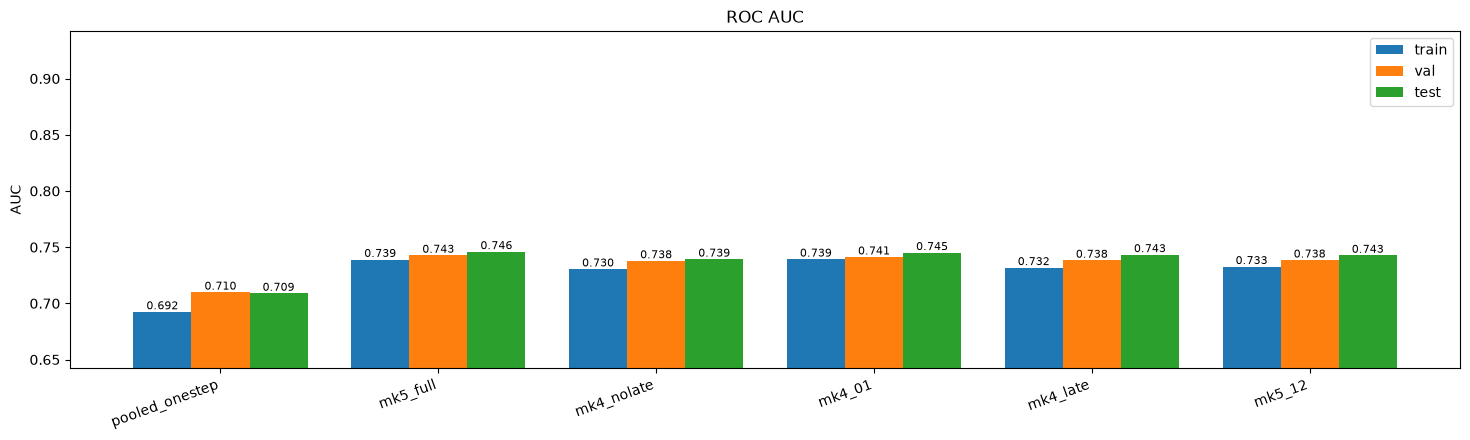

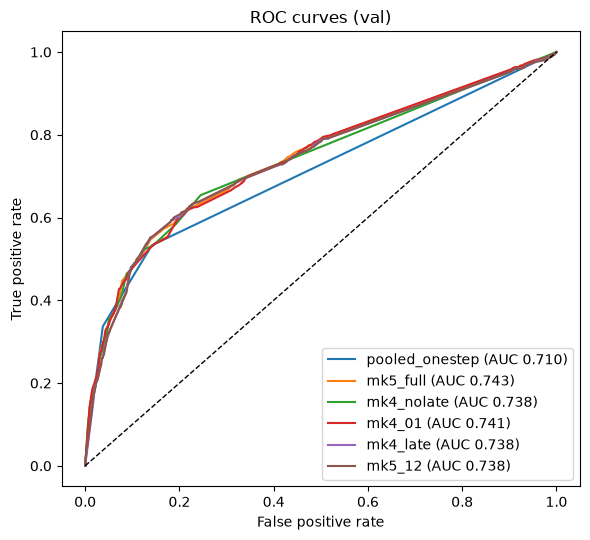

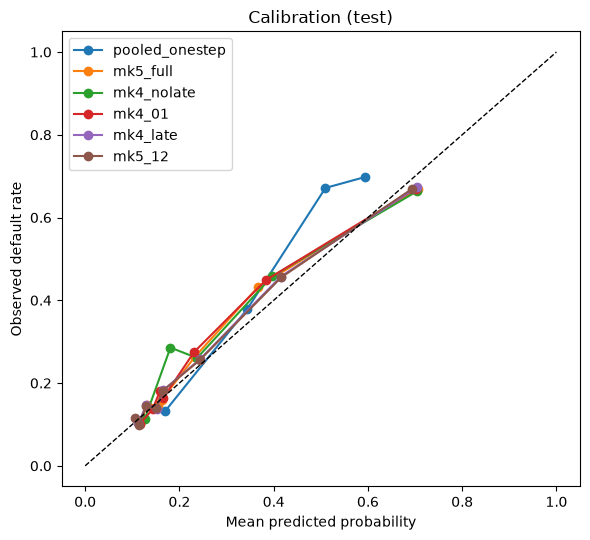

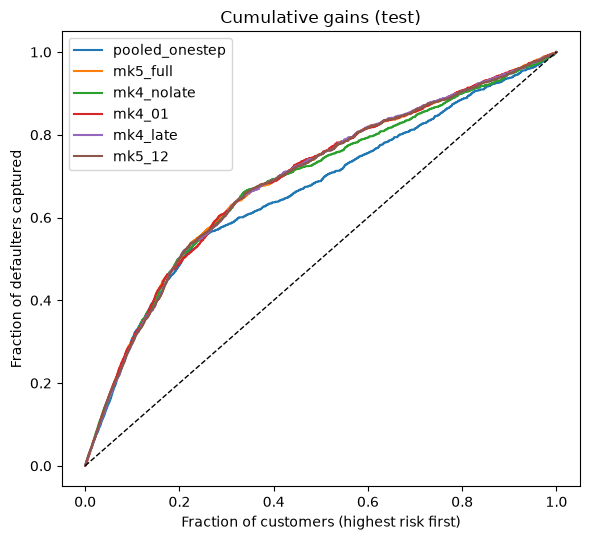

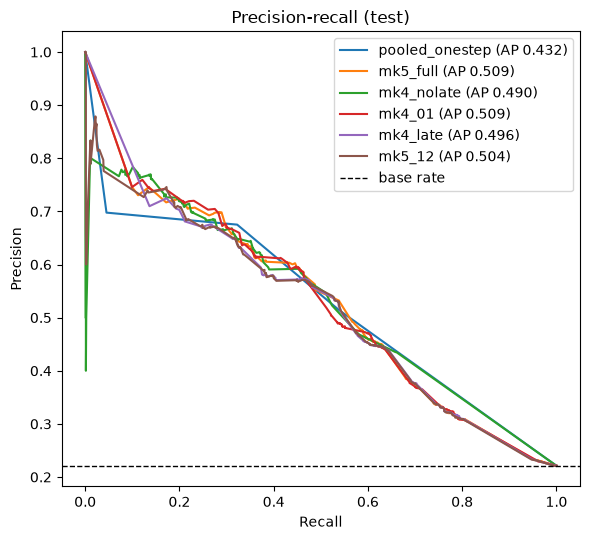

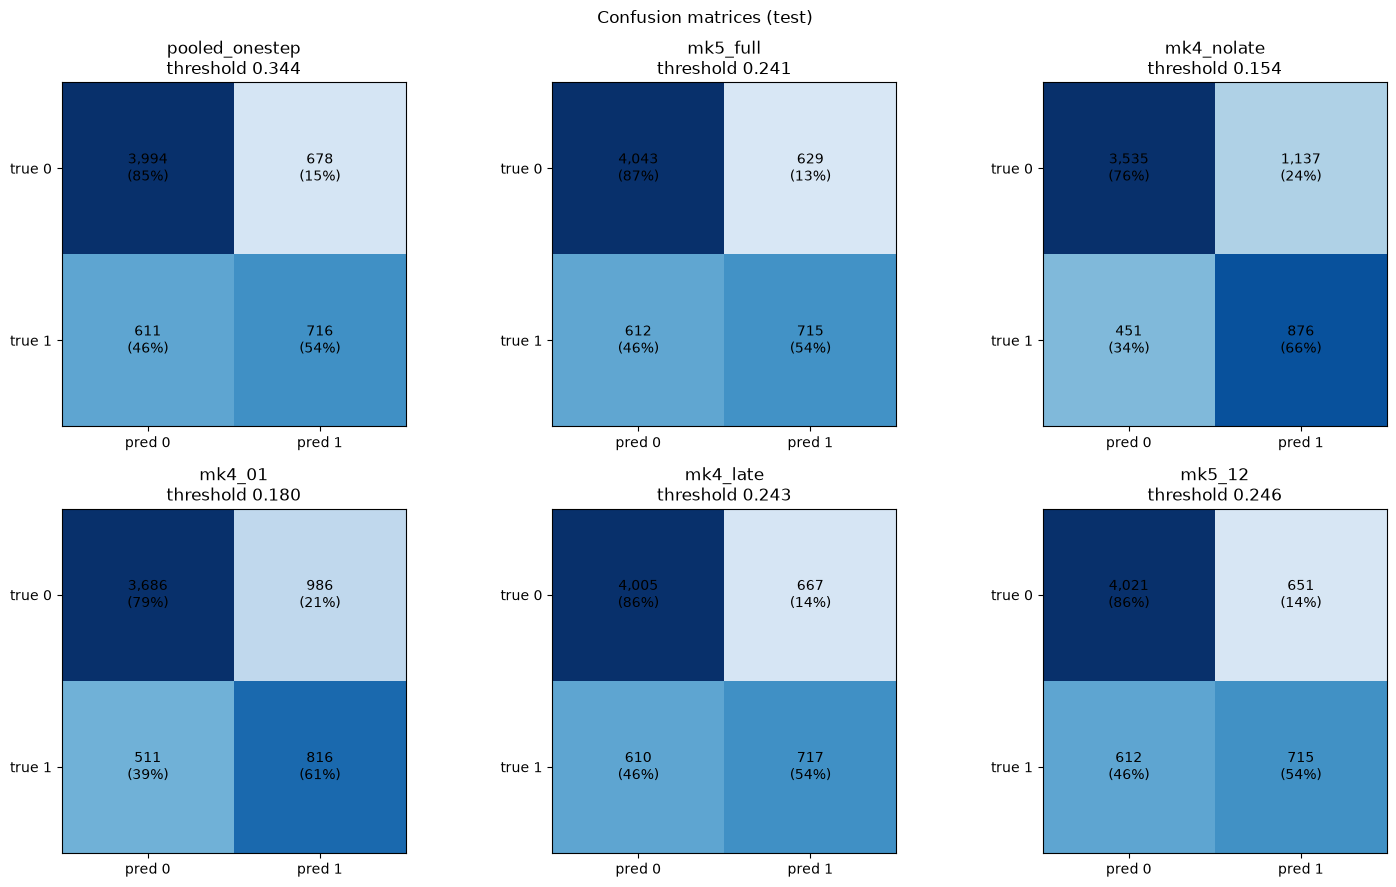

In [ ]:
pooled = dict(p_tr=predict_onestep(S_tr), p_va=p_mk_onestep_va, p_te=p_mk_onestep_te)

compare = {"pooled_onestep": pooled, **markov_models,**markov_models2}
plot_auc(compare)
plot_roc(compare, split="val")
plot_calibration(compare, split="test")
plot_gains(compare)
plot_pr(compare)
plot_confusion(compare, split="test")




Improvement from original model can be seen clearly. Decide on which one or two to continue experimenting with: Likely mk_4_01 and mk_4_no late, could also make another split with inspiration from both models.

## Add Outstanding Balance Markov/ Include Bill/ Amt data in modelling.